In [1]:
import os
import time
import sys
import clr
import numpy as np
import matplotlib.pyplot as plt
from slmcontrol import *
import time 
from pylablib.devices import Thorlabs
from slmcontrol import *
from cameras.Ximea import XimeaCamera
from cameras.ImagingSource import ImagingSourceCamera
from tqdm import tqdm

# Add References to .NET libraries

clr.AddReference("C:\\Program Files\\Thorlabs\\Kinesis\\Thorlabs.MotionControl.DeviceManagerCLI.dll")
clr.AddReference("C:\\Program Files\\Thorlabs\\Kinesis\\Thorlabs.MotionControl.GenericMotorCLI.dll")
clr.AddReference("C:\\Program Files\\Thorlabs\\Kinesis\\ThorLabs.MotionControl.KCube.StepperMotorCLI.dll")
from Thorlabs.MotionControl.DeviceManagerCLI import *
from Thorlabs.MotionControl.GenericMotorCLI import *
from Thorlabs.MotionControl.KCube.StepperMotorCLI import *
from System import Decimal  # necessary for real world units

#input beam



#PARA O EXPERIMENTO RODA ESSE

In [ ]:

camera = ImagingSourceCamera()



#input beam
slm = SLMdisplay(monitor=1)
config_path = 'config.ini'
config = configparser.ConfigParser()
config.read(config_path)
x,y = build_grid(config_path)
input = hg(x,y,0,0,config['incoming'].getfloat('waist'))

stage_z = Thorlabs.kinesis.KinesisMotor('26005619',scale='ZST',  default_channel=2, is_rack_system=False)
print(f" stage z  -- {stage_z.get_position(scale= 'ZST')}")
stages = [stage_z]

for _ in stages:
    print(_.is_homed())
    if _.is_homed() == False:
        _.home()
for _ in stages:
    _.wait_for_home()

resolution = 100
step_size = 100e-9

stage_z.move_to(0.004) # in meter
stage_z.wait_move()


#laguerre vai até quanto?


#data = np.empty((resolution,ls,480, 640),dtype="uint8")
data = np.empty((resolution,480, 640),dtype="uint8")

n = 2
m = 1

desired = hg(x, y, n, m, .5)
holo = generate_hologram(desired,input,x,y,195,3,4,0,0,method='bessel1')
slm.updateArray(holo)


for i in range(resolution):
    stage_z.move_by(step_size)
    stage_z.wait_move()
    time.sleep(0.15)
    data[i] = camera.capture()

camera.close()



 stage z  -- 0.004009956699032074
True


In [3]:
np.savez(f'amostra600_hg{n}{m}_step100e-9_Resolution{resolution}', data)

In [ ]:
camera.close()

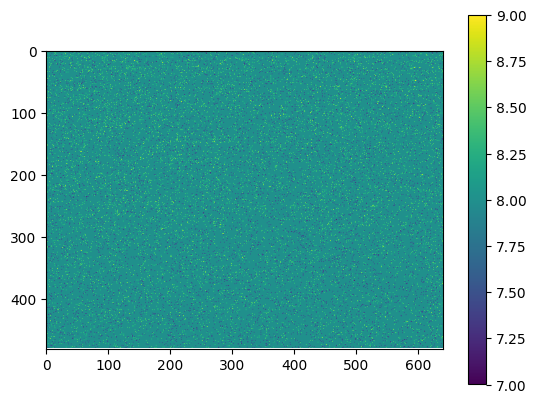

In [5]:
data = np.load('amostra600_hg21_step100e-9_Resolution100.npz')['arr_0']
cut = data < 250
data = data*cut
plt.imshow(data[0])
plt.colorbar()